In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('stud.csv')
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


**We are going to predict the math_Score from here**

**EDA**

In [3]:
numerical_col=df.select_dtypes(include='number')
cat_col=df.select_dtypes(exclude='number')
numerical_col.columns

Index(['math_score', 'reading_score', 'writing_score'], dtype='str')

In [4]:
df_cleaned=df.copy()

In [5]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [6]:
df_cleaned.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


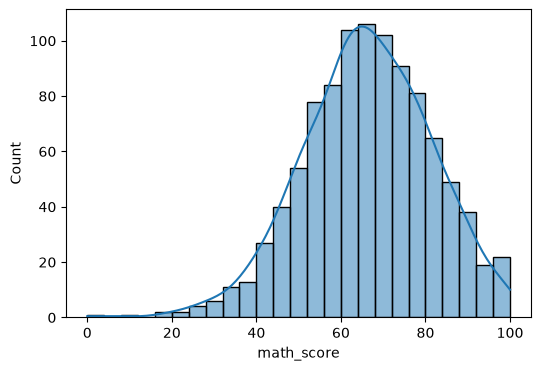

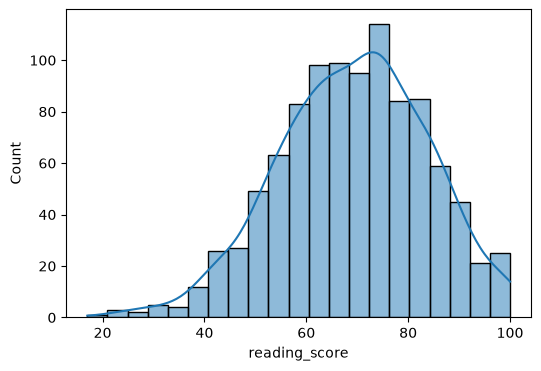

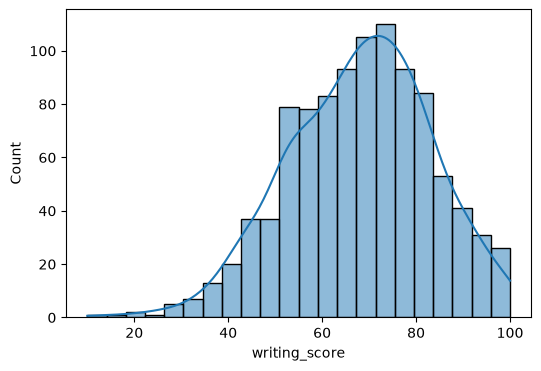

In [7]:
for col in numerical_col:
    plt.figure(figsize=(6,4),dpi=100)
    sns.histplot(df_cleaned[col],kde=True)

In [8]:
df_cleaned.isnull().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [9]:
df_cleaned.shape

(1000, 8)

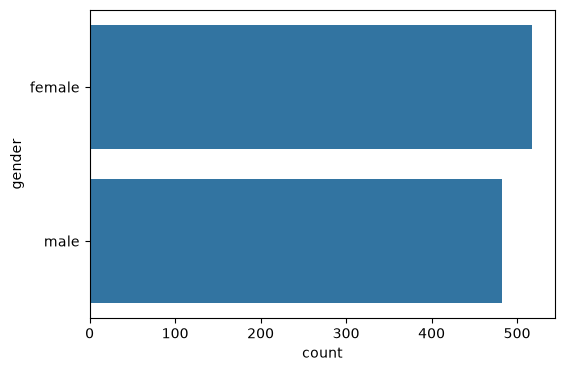

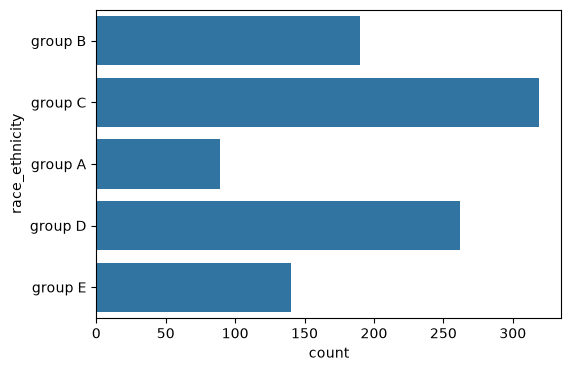

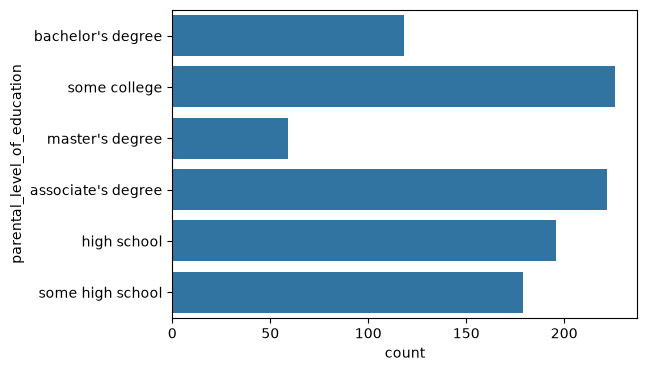

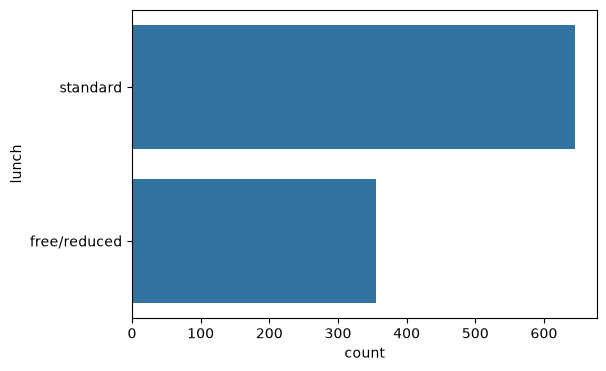

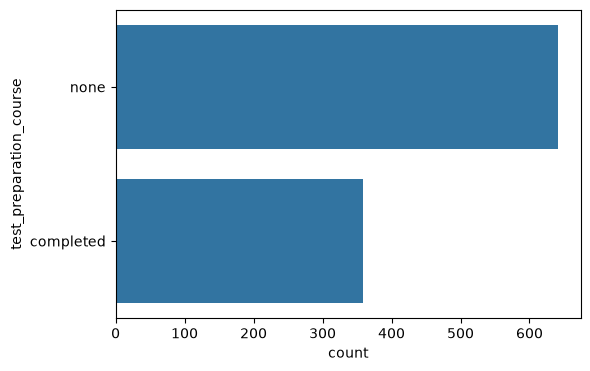

In [10]:
for col in cat_col:
    plt.figure(figsize=(6,4),dpi=100)
    sns.countplot(df[col])

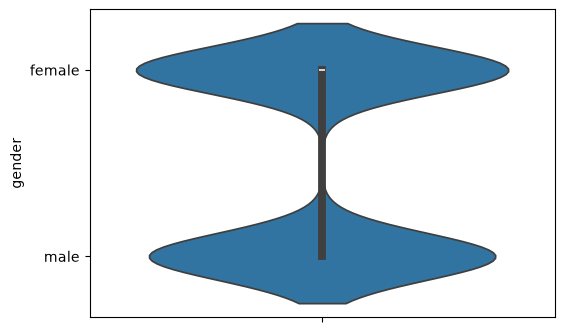

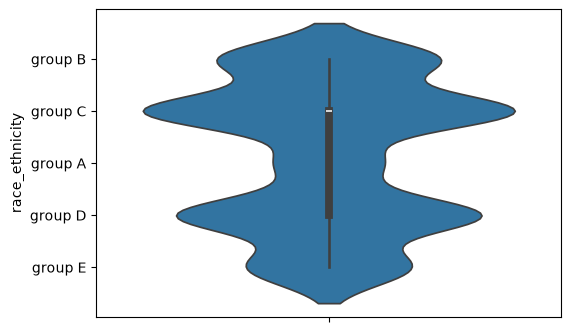

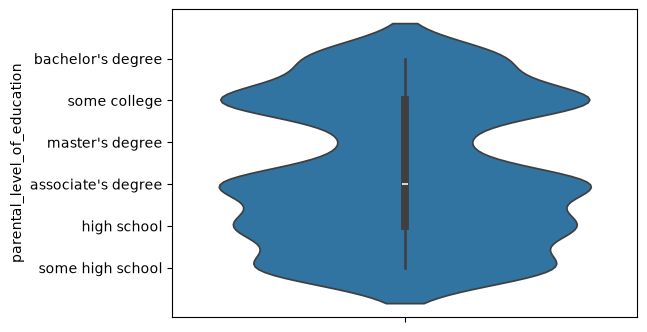

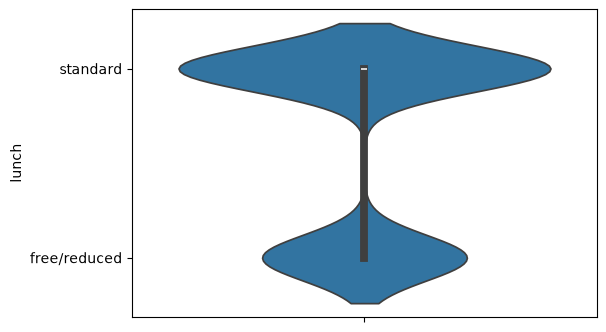

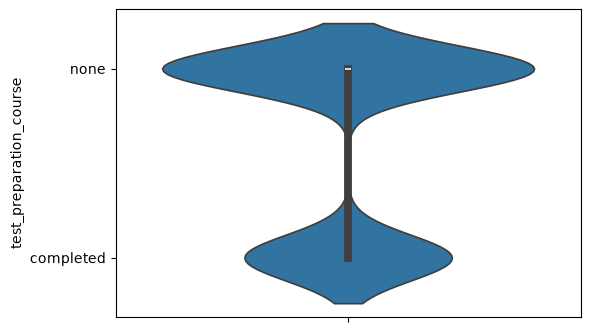

In [11]:
for col in cat_col:
    plt.figure(figsize=(6,4),dpi=100)
    sns.violinplot(df[col])

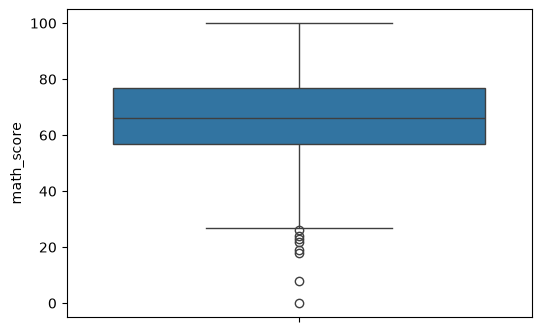

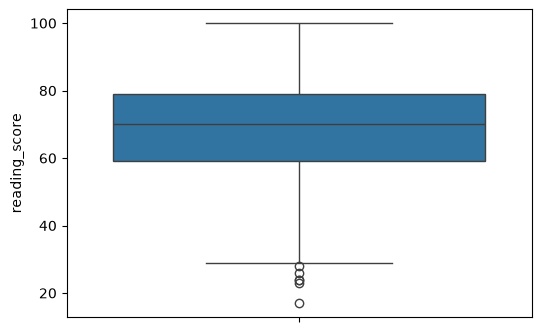

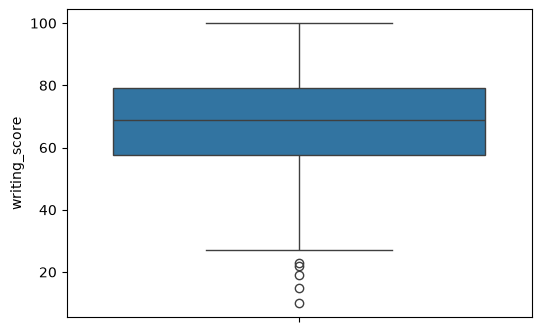

In [12]:
for col in numerical_col:
    plt.figure(figsize=(6,4),dpi=100)
    sns.boxplot(df[col])

**Next we must check the outlier count in each numerical col**

In [13]:
for col in numerical_col:
    print("Column name : ",col,"  skew_ness_value : ",df_cleaned[col].skew())

Column name :  math_score   skew_ness_value :  -0.27893514909431694
Column name :  reading_score   skew_ness_value :  -0.25910451810923063
Column name :  writing_score   skew_ness_value :  -0.28944397150761897


In [14]:
def outliers_count(col):
    outlier_count=0
    Q1=np.percentile(df_cleaned[col],25)
    Q3=np.percentile(df_cleaned[col],75)

    IQR=Q3-Q1

    LF=Q1-(1.5*IQR)
    UF=Q3+(1.5*IQR)

    for val in df_cleaned[col]:
        if val <= LF or val >= UF:
            outlier_count+=1

    return outlier_count

In [15]:
for col in numerical_col:
    print("Column name :",col," Outlier_count: ",outliers_count(col))

Column name : math_score  Outlier_count:  10
Column name : reading_score  Outlier_count:  8
Column name : writing_score  Outlier_count:  5


In [16]:
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,OrdinalEncoder

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
from sklearn.impute import SimpleImputer

In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [21]:
numerical_col.columns

Index(['math_score', 'reading_score', 'writing_score'], dtype='str')

In [22]:
numerical_col=numerical_col.drop(columns=['math_score'])

In [23]:
numerical_col.columns

Index(['reading_score', 'writing_score'], dtype='str')

In [24]:
numerical_pipeline=Pipeline(steps=[
    ('simpleimputer',SimpleImputer(strategy='median')),
    ('standard_Scalar',StandardScaler())   
])

In [25]:
categorical_pipeline=Pipeline([
    ('simpleimputer',SimpleImputer(strategy='most_frequent')),
    ('one_hot',OneHotEncoder(handle_unknown='ignore')),
])

In [26]:
preprocessor=ColumnTransformer(transformers=[
    ('numerical',numerical_pipeline,numerical_col.columns),
    ('cat_',categorical_pipeline,cat_col.columns)
])

In [27]:
df_cleaned.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='str')

In [28]:
X=df_cleaned.drop('math_score',axis=1)
y=df_cleaned['math_score']

In [29]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [30]:
from sklearn.linear_model import LinearRegression

In [31]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import AdaBoostRegressor,GradientBoostingRegressor

In [32]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
import xgboost
from xgboost import XGBRegressor

In [34]:
linear_model_pipeline=Pipeline(
    steps=[
        ('preprocessing',preprocessor),
        ('linear_model',LinearRegression())
    ]
)

In [35]:
linear_model_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('linear_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['gender','race_ethnicity','parental_level_of_education',..., 'test_preparation_course','reading_score','writing_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('cat_', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit

In [36]:
y_pred=linear_model_pipeline.predict(X_test)

In [37]:
from sklearn.metrics import r2_score,root_mean_squared_error,mean_absolute_error

In [38]:
print(r2_score(y_pred=y_pred,y_true=y_test))

0.8804332983749565


In [39]:
print(root_mean_squared_error(y_pred=y_pred,y_true=y_test))

5.393993869732841


In [40]:
random_forest_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('random_forest',RandomForestRegressor(n_estimators=100))
])
random_forest_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['gender','race_ethnicity','parental_level_of_education',..., 'test_preparation_course','reading_score','writing_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('cat_', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit

In [42]:
y_pred_random=random_forest_pipeline.predict(X_test)
r2_score(y_pred=y_pred_random,y_true=y_test)

0.855102372283367

In [43]:
adagrad_pipeline=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('ada_model',AdaBoostRegressor())
])
adagrad_pipeline.fit(X_train,y_train)
y_pred_ada=adagrad_pipeline.predict(X_test)
print(r2_score(y_pred_ada,y_test))

0.7982375061583609


**Next we want to do HyperParameter Tuning**

In [44]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV

In [53]:
linear_model_grid_search = GridSearchCV(
    estimator=linear_model_pipeline,
    param_grid={
        'linear_model__fit_intercept': [True, False],
        'linear_model__positive': [True, False],
        'linear_model__copy_X': [True, False]
},
    cv=5,
)


In [54]:
linear_model_grid_search.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'linear_model__copy_X': [True, False], 'linear_model__fit_intercept': [True, False], 'linear_model__positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"v

In [55]:
y_pred_linear_grid_search=linear_model_grid_search.predict(X_test)
print(r2_score(y_pred=y_pred_linear_grid_search,y_true=y_test))

0.8804332983749565
